# Cleaning and Exploring Real Data: Medical Appointment No-Shows
**A hands-on lesson in data selection and preparation**

Real data is never ready to use the day you get it. This notebook works through a real dataset in the same order a data team does:

- **Part 1: Check and clean.** Find every problem that must be fixed before anyone can use the data. Then fix it and record each decision.
- **Part 2: Explore.** With clean data, look for patterns: who is in the data, what predicts a missed appointment, and which patterns can fool you.
- **Part 3: Split, train, and test.** Split the data the right way, train a simple model, and test it honestly. See how a score can fool you.

**The dataset.** Public health clinics in Vitória, Brazil, recorded every appointment from late April to early June 2016: 110,527 appointments. Each row is one appointment. The `No-show` column says whether the patient missed it.

Source: Joni Hoppen and Aquarela Advanced Analytics, *Medical Appointment No Shows*, published on Kaggle (2016). License: Creative Commons Attribution-NonCommercial-ShareAlike 4.0 (CC BY-NC-SA 4.0). Used here for teaching.

### How to run this notebook
- Select a gray code cell, then press **Shift + Enter** to run it. The result appears under the cell.
- Run the cells **in order, from top to bottom**. Later cells use results from earlier ones.
- To run everything at once, select **Runtime**, then **Run all**.
- You do not need to change any code. Read each explanation, run the cell, then read **What to notice**.

### The five data quality dimensions
Every problem in Part 1 fits one of these.

| Dimension | The question it asks |
|---|---|
| Accuracy | Do the values match reality? |
| Completeness | Is anything missing? |
| Consistency | Is the same thing recorded the same way everywhere? |
| Timeliness | Is the data current enough for the purpose? |
| Representativeness | Does the data match the people the system will serve? |

---
# Part 1: Check and clean
In Part 1 you only **look for problems**. You change nothing until Step 9. Checking first and cleaning second keeps you from fixing one problem in a way that hides another.

## Step 1. Load the data
**What this does.** The first lines load **pandas**, the standard Python tool for tables of data, and **matplotlib**, a tool for charts. The rest reads the data file, a CSV (comma-separated values) file, into a table called `df` (short for *data frame*, pandas' name for a table). The file is about 11 megabytes (MB), so loading takes a few seconds.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Show every column when we print a table
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

# Where the data file lives
DATA_URL = "https://raw.githubusercontent.com/cynthialmcginnis/arin320-data/main/noshow_appointments.csv"

try:
    df = pd.read_csv(DATA_URL)
    print("Loaded the data.")
except Exception:
    # Backup: upload the CSV file from your own computer
    from google.colab import files
    print("Could not reach GitHub. Select 'Choose Files' and upload the file noshow_appointments.csv.")
    uploaded = files.upload()
    df = pd.read_csv(list(uploaded.keys())[0])

print("Rows:", f"{len(df):,}")
print("Columns:", df.shape[1])

Loaded the data.
Rows: 110,527
Columns: 14


**What to notice.** 110,527 rows and 14 columns. Each row is one **appointment**, not one patient. That matters in Part 2.

## Step 2. Take a first look
**What this does.** `head()` shows the first five rows. Before running any test, look at the raw data with your own eyes.

In [2]:
df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


**What to notice.**
- **Misspelled column names:** `Hipertension` and `Handcap`. Someone who types the correct spelling later gets an error.
- **The label reads backwards.** In `No-show`, `No` means the patient **showed up**. `Yes` means the patient **missed**. A team that reads it the wrong way builds a model that predicts the opposite of what they think.
- **Every appointment time is `00:00:00`.** The booking time has a real clock time. The appointment does not.
- `Scholarship` means the patient is enrolled in Bolsa Família, a Brazilian welfare program for low-income families.

**Add to the cleaning list:** fix the column names, replace the backwards label.

## Step 3. Check the data type of each column
**What this does.** Every column has a **data type**: whole numbers (`int64`), decimal numbers (`float64`), or text (`object`; newer versions of pandas show `str`). The wrong type causes quiet errors.

In [3]:
df.dtypes

PatientId         float64
AppointmentID       int64
Gender                str
ScheduledDay          str
AppointmentDay        str
Age                 int64
Neighbourhood         str
Scholarship         int64
Hipertension        int64
Diabetes            int64
Alcoholism          int64
Handcap             int64
SMS_received        int64
No-show               str
dtype: object

**What to notice.**
- `PatientId` is stored as a **decimal number**. An ID (identifier) is a label, not a quantity. You never add or average IDs.
- `ScheduledDay` and `AppointmentDay` are stored as **text**. Python cannot subtract one date from another until they are real dates.

The next cell shows why a decimal ID is a problem.

In [4]:
# A real patient ID is a whole number. Find any that are not.
odd_ids = df[df["PatientId"] % 1 != 0]["PatientId"]
print("Patient IDs with a decimal part:", len(odd_ids))
print(odd_ids.tolist())

Patient IDs with a decimal part: 5
[93779.52927, 537615.28476, 141724.16655, 39217.84439, 43741.75652]


**What to notice.** 5 patient IDs have decimals, like `93779.52927`. No real ID looks like that. **Dimension: accuracy.**

**Add to the cleaning list:** store the ID as text, convert the dates.

## Step 4. Look for missing values (NaN)
**What this does.** In pandas, a blank cell is called **NaN** ("not a number"). `isna().sum()` counts the blanks in each column.

In [5]:
df.isna().sum()

PatientId         0
AppointmentID     0
Gender            0
ScheduledDay      0
AppointmentDay    0
Age               0
Neighbourhood     0
Scholarship       0
Hipertension      0
Diabetes          0
Alcoholism        0
Handcap           0
SMS_received      0
No-show           0
dtype: int64

**What to notice.** Every count is **0**. There are no blank cells. Data websites report this dataset as having no missing values.

That does **not** mean nothing is missing. A data entry system that cannot leave a field blank fills it with something that looks normal, like `0` or midnight. Watch for three disguised gaps in the next steps:
1. **Appointment time:** always midnight. (Step 6)
2. **Age 0:** a baby, or "age unknown"? (Step 5)
3. **Handcap:** described as yes or no, but it holds five different values. (Step 5)

**Lesson:** a NaN count of zero is where checking for missing data starts, not where it ends. **Dimension: completeness.**

## Step 5. Look for impossible and suspicious values
**What this does.** `describe()` gives the count, average (`mean`), spread (`std`, standard deviation), smallest value (`min`), largest value (`max`), and quartiles for every number column. The **min** and **max** rows are the fastest way to spot impossible values.

In [6]:
df[["Age", "Scholarship", "Hipertension", "Diabetes", "Alcoholism", "Handcap", "SMS_received"]].describe().round(2)

,Age,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received
count,110527.00,110527.0,110527.0,110527.00,110527.00,110527.00,110527.00
mean,37.09,0.1,0.2,0.07,0.03,0.02,0.32
std,23.11,0.3,0.4,0.26,0.17,0.16,0.47
min,-1.00,0.0,0.0,0.00,0.00,0.00,0.00
25%,18.00,0.0,0.0,0.00,0.00,0.00,0.00
50%,37.00,0.0,0.0,0.00,0.00,0.00,0.00
75%,55.00,0.0,0.0,0.00,0.00,0.00,1.00
max,115.00,1.0,1.0,1.00,1.00,4.00,1.00


**What to notice.**
- **Age min is -1.** No one is -1 years old.
- **Age max is 115.** Possible, but very rare.
- **Handcap max is 4.** Every other yes-or-no column stops at 1.

In [7]:
print("Appointments with age below 0:  ", (df["Age"] < 0).sum())
print("Appointments with age 0:        ", (df["Age"] == 0).sum())
print("Appointments with age over 100: ", (df["Age"] > 100).sum())
print()
df[df["Age"] > 100][["PatientId", "Age", "Gender", "Neighbourhood", "AppointmentDay"]]

Appointments with age below 0:   1
Appointments with age 0:         3539
Appointments with age over 100:  7



,PatientId,Age,Gender,Neighbourhood,AppointmentDay
58014,9.762948e+14,102,F,CONQUISTA,2016-05-03T00:00:00Z
63912,3.196321e+13,115,F,ANDORINHAS,2016-05-19T00:00:00Z
63915,3.196321e+13,115,F,ANDORINHAS,2016-05-19T00:00:00Z
68127,3.196321e+13,115,F,ANDORINHAS,2016-05-16T00:00:00Z
76284,3.196321e+13,115,F,ANDORINHAS,2016-05-30T00:00:00Z
90372,2.342836e+11,102,F,MARIA ORTIZ,2016-06-02T00:00:00Z
97666,7.482346e+14,115,F,SÃO JOSÉ,2016-06-03T00:00:00Z


**What to notice.**
- **One appointment has age -1.** An error. **Dimension: accuracy.**
- **Seven appointments list age 102 or 115.** One 115-year-old patient appears **four times**. Very few people anywhere live to 115, so these are likely errors. 102 is possible.
- **Age 0 appears 3,539 times.** A public clinic sees many babies, so most are real. The data cannot tell you which are babies and which are "unknown."

**Error or real?** The numbers alone cannot decide. Software flags the value. A person who knows the clinic decides what it means.

In [8]:
# Medical conditions that are very unlikely in young children
print("Children under 12 recorded with alcoholism:   ", ((df["Age"] < 12) & (df["Alcoholism"] == 1)).sum())
print("Children under 10 recorded with hypertension: ", ((df["Age"] < 10) & (df["Hipertension"] == 1)).sum())
print()
print("Handcap values:")
print(df["Handcap"].value_counts().sort_index())

Children under 12 recorded with alcoholism:    6
Children under 10 recorded with hypertension:  8

Handcap values:
Handcap
0    108286
1      2042
2       183
3        13
4         3
Name: count, dtype: int64


**What to notice.**
- 6 children under 12 are recorded with alcoholism, and 8 children under 10 with hypertension (high blood pressure). Each value is legal on its own. The **combination** is suspicious. Checks like this come from the field itself, so they are called **domain checks**.
- **Handcap** holds 0, 1, 2, 3, and 4. The dataset's description calls it yes or no. It most likely counts disabilities, but nobody wrote that down. A model would read 4 as "four times" 1. **Dimension: consistency.**

**Add to the cleaning list:** remove the age of -1, flag ages over 100 for review, add a clear yes/no disability column.

## Step 6. Check the dates
**What this does.** We convert the two date columns from text to real dates. Then we compute `wait_days`, the number of days from booking to appointment, and look for dates that make no sense.

In [9]:
df["ScheduledDay"] = pd.to_datetime(df["ScheduledDay"])
df["AppointmentDay"] = pd.to_datetime(df["AppointmentDay"])

# Days from the booking date to the appointment date
df["wait_days"] = (df["AppointmentDay"].dt.normalize() - df["ScheduledDay"].dt.normalize()).dt.days

print("Appointments run from", df["AppointmentDay"].min().date(), "to", df["AppointmentDay"].max().date())
print("Different appointment dates:", df["AppointmentDay"].dt.date.nunique())
print("Appointments with a real clock time (not midnight):", (df["AppointmentDay"].dt.hour > 0).sum())
print("Appointments dated BEFORE they were booked:", (df["wait_days"] < 0).sum())
print()
df[df["wait_days"] < 0][["PatientId", "ScheduledDay", "AppointmentDay", "wait_days", "No-show"]]

Appointments run from 2016-04-29 to 2016-06-08
Different appointment dates: 27
Appointments with a real clock time (not midnight): 0
Appointments dated BEFORE they were booked: 5



,PatientId,ScheduledDay,AppointmentDay,wait_days,No-show
27033,7.839273e+12,2016-05-10 10:51:53+00:00,2016-05-09 00:00:00+00:00,-1,Yes
55226,7.896294e+12,2016-05-18 14:50:41+00:00,2016-05-17 00:00:00+00:00,-1,Yes
64175,2.425226e+13,2016-05-05 13:43:58+00:00,2016-05-04 00:00:00+00:00,-1,Yes
71533,9.982316e+14,2016-05-11 13:49:20+00:00,2016-05-05 00:00:00+00:00,-6,Yes
72362,3.787482e+12,2016-05-04 06:50:57+00:00,2016-05-03 00:00:00+00:00,-1,Yes


**What to notice.**
- **5 appointments happened 1 to 6 days before they were booked.** Impossible. All 5 are marked as missed, which suggests a cancellation or entry error, not a real patient. **Dimension: accuracy.**
- **Zero appointments have a clock time.** We know when patients booked down to the second, but not what time of day the appointment was. If time of day affects attendance, no model can learn it from this data. That gap cannot be cleaned. It can only be written down. **Dimension: completeness.**
- **The data covers 27 days in 2016.** It misses holidays, seasons, and everything that changed after 2016. Cleaning cannot fix that either. **Dimension: timeliness.**

**Add to the cleaning list:** remove the 5 impossible appointments.

## Step 7. Look for duplicate records
**What this does.** `duplicated()` finds rows that repeat. First we look for exact copies. Then we ignore the appointment ID and look again.

In [10]:
print("Exact duplicate rows:", df.duplicated().sum())

same_booking = ["PatientId", "ScheduledDay", "AppointmentDay"]
print("Same patient, same booking time, same appointment day:", df.duplicated(same_booking).sum())

groups = df[df.duplicated(same_booking, keep=False)].groupby(same_booking)
disagree = groups["No-show"].nunique() > 1
print("Of those groups, how many disagree about whether the patient came:", disagree.sum())

Exact duplicate rows: 0
Same patient, same booking time, same appointment day: 1334
Of those groups, how many disagree about whether the patient came: 29


**What to notice.**
- No row is an exact copy. But **1,334** appointments repeat the same patient, booked at the same second, for the same day, with a **different appointment ID**. The new ID hid them from the simple check.
- In **29** of those groups, the same booking is marked **both** "showed up" and "missed." Both cannot be true. **Dimension: consistency.**

Some repeats may be real, such as two services on one day. Others may be double entries. Only the clinic knows.

**Add to the cleaning list:** flag the repeat bookings and the conflicting ones for the clinic to review.

## Step 8. The cleaning to-do list
**What this does.** We collect every problem from Steps 2 to 7 into one table, sorted by dimension. A written list like this is the first part of an **evaluation protocol**.

In [11]:
conflict_keys = disagree[disagree].index
report = pd.DataFrame([
    ["Accuracy",     "Age below 0",                                (df["Age"] < 0).sum(),                    "Remove"],
    ["Accuracy",     "Appointment dated before booking",           (df["wait_days"] < 0).sum(),              "Remove"],
    ["Accuracy",     "Age over 100",                               (df["Age"] > 100).sum(),                  "Flag for review"],
    ["Accuracy",     "Patient ID with a decimal",                  (df["PatientId"] % 1 != 0).sum(),         "Store ID as text"],
    ["Accuracy",     "Child with alcoholism or hypertension",      (((df["Age"] < 12) & (df["Alcoholism"] == 1)) | ((df["Age"] < 10) & (df["Hipertension"] == 1))).sum(), "Flag for review"],
    ["Completeness", "Appointment with no clock time",             (df["AppointmentDay"].dt.hour == 0).sum(), "Cannot fix. Document it."],
    ["Completeness", "Age recorded as 0",                          (df["Age"] == 0).sum(),                   "Keep. Most are babies."],
    ["Consistency",  "Handcap above 1 in a yes/no column",         (df["Handcap"] > 1).sum(),                "Add a yes/no column"],
    ["Consistency",  "Repeat booking with a new appointment ID",   df.duplicated(same_booking).sum(),        "Flag for review"],
    ["Consistency",  "Misspelled column names",                    2,                                        "Rename"],
    ["Consistency",  "Backwards label (No = showed up)",           1,                                        "Replace with 'missed'"],
    ["Timeliness",   "Days of appointments covered (2016)",        df["AppointmentDay"].dt.date.nunique(),   "Cannot fix. Document it."],
], columns=["Dimension", "Problem", "Count", "Decision"])
report

,Dimension,Problem,Count,Decision
0,Accuracy,Age below 0,1,Remove
1,Accuracy,Appointment dated before booking,5,Remove
2,Accuracy,Age over 100,7,Flag for review
3,Accuracy,Patient ID with a decimal,5,Store ID as text
4,Accuracy,Child with alcoholism or hypertension,14,Flag for review
5,Completeness,Appointment with no clock time,110527,Cannot fix. Document it.
6,Completeness,Age recorded as 0,3539,Keep. Most are babies.
7,Consistency,Handcap above 1 in a yes/no column,199,Add a yes/no column
8,Consistency,Repeat booking with a new appointment ID,1334,Flag for review
9,Consistency,Misspelled column names,2,Rename


**What to notice.** Only two problems call for removing rows. Most call for a flag, a new column, or a written note. Two cannot be fixed at all. They limit what any model trained on this data can do, and anyone using the data needs to know that.

## Step 9. Clean the data
**What this does.** We apply every decision from the to-do list to a **copy** called `clean`, so the original stays untouched. Each step is written down, so someone else can repeat it exactly on new data.

In [12]:
clean = df.copy()
start = len(clean)

# 1. Remove impossible records: negative age, or appointment before booking
clean = clean[(clean["Age"] >= 0) & (clean["wait_days"] >= 0)].copy()

# 2. Replace the backwards label with a clear one: 1 = missed, 0 = showed up
clean["missed"] = (clean["No-show"] == "Yes").astype(int)
clean = clean.drop(columns=["No-show"])

# 3. Fix the misspelled column names
clean = clean.rename(columns={"Hipertension": "Hypertension", "Handcap": "Disability_count"})

# 4. Add a clear yes/no disability column, and keep the count
clean["has_disability"] = (clean["Disability_count"] > 0).astype(int)

# 5. Store the patient ID as text, since it is a label, not a number
clean["PatientId"] = clean["PatientId"].astype(str)

# 6. Flag records for a person to review, instead of deleting them
clean["review_age"] = (clean["Age"] > 100).astype(int)
clean["review_condition"] = (((clean["Age"] < 12) & (clean["Alcoholism"] == 1)) |
                             ((clean["Age"] < 10) & (clean["Hypertension"] == 1))).astype(int)
clean["review_repeat"] = clean.duplicated(same_booking, keep=False).astype(int)

print(f"Rows before cleaning: {start:,}")
print(f"Rows after cleaning:  {len(clean):,}")
print(f"Rows removed:         {start - len(clean)}")
print()
print("Records flagged for review:")
print(clean[["review_age", "review_condition", "review_repeat"]].sum())

Rows before cleaning: 110,527
Rows after cleaning:  110,521
Rows removed:         6

Records flagged for review:
review_age             7
review_condition      14
review_repeat       2609
dtype: int64


**What to notice.** We removed only **6** rows: the age of -1 and the 5 appointments dated before booking. Everything else stays, with flags. We did **not** delete:
- **Ages over 100.** Deleting real elderly patients removes a group.
- **Repeat bookings.** We do not yet know which are errors.
- **Age 0.** Deleting them removes every infant.

Each choice is a judgment call, and a different team could defend different choices. What matters is that the choices are made on purpose and written down.

## Step 10. Check that the cleaning worked
**What this does.** Never assume a cleaning step worked. Run the checks again on the clean copy.

In [13]:
print("Smallest age:       ", clean["Age"].min())
print("Shortest wait:      ", clean["wait_days"].min(), "days")
print("Label values:       ", sorted(clean["missed"].unique()))
print("Patient ID type:    ", clean["PatientId"].dtype)
print("Columns now:")
print(list(clean.columns))

Smallest age:        0
Shortest wait:       0 days
Label values:        [np.int64(0), np.int64(1)]
Patient ID type:     str
Columns now:
['PatientId', 'AppointmentID', 'Gender', 'ScheduledDay', 'AppointmentDay', 'Age', 'Neighbourhood', 'Scholarship', 'Hypertension', 'Diabetes', 'Alcoholism', 'Disability_count', 'SMS_received', 'wait_days', 'missed', 'has_disability', 'review_age', 'review_condition', 'review_repeat']


**What to notice.** No negative ages, no negative waits, a clear 0/1 label, and correct column names. The clean data is ready to explore.

---
# Part 2: Explore the clean data
Now we look for patterns. Every cell from here on uses `clean`, not `df`.

## Step 11. Who is in the data?
**What this does.** Before asking what predicts a missed appointment, check who the data describes. A model only learns about the people in its data. A **histogram** shows how numeric data is spread out. It divides the number line into equal ranges called **bins**, here 2 years of age each. Each bin's height shows how many records fall in that range. Unlike a bar chart, which compares separate categories and has gaps between its bars, a histogram's bins touch, because one range ends where the next begins.

Appointments by gender:
Gender
F    0.65
M    0.35
Name: proportion, dtype: float64

Different neighborhoods: 81
Largest: JARDIM CAMBURI with 7717 appointments
Smallest five:
Neighbourhood
ILHA DO BOI                    35
ILHA DO FRADE                  10
AEROPORTO                       8
ILHAS OCEÂNICAS DE TRINDADE     2
PARQUE INDUSTRIAL               1
Name: count, dtype: int64


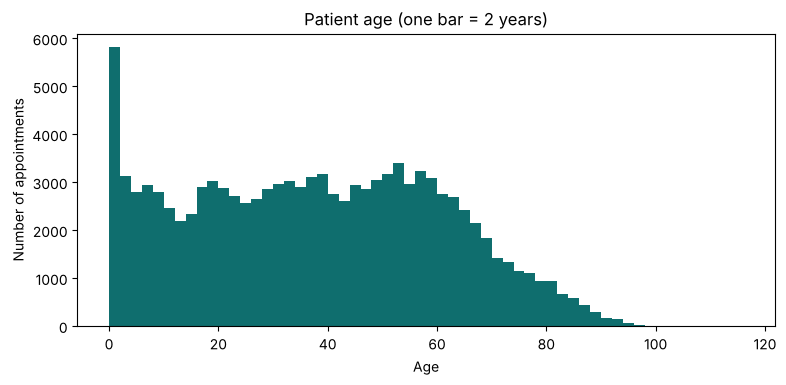

In [14]:
print("Appointments by gender:")
print(clean["Gender"].value_counts(normalize=True).round(2))
print()

counts = clean["Neighbourhood"].value_counts()
print("Different neighborhoods:", counts.size)
print("Largest:", counts.index[0], "with", counts.iloc[0], "appointments")
print("Smallest five:")
print(counts.tail(5))

plt.figure(figsize=(9, 3.8))
plt.hist(clean["Age"], bins=range(0, 118, 2), color="#0f6e6e")
plt.title("Patient age (one bar = 2 years)")
plt.xlabel("Age")
plt.ylabel("Number of appointments")
plt.show()

**What to notice.**
- **65 percent of appointments are women.** A model learns women's patterns from more examples than men's.
- **One neighborhood has 1 appointment, and another has 2.** The model knows almost nothing about patients from those places.
- **The tallest age bar is 0 to 2.** Many babies, plus any "unknown" ages entered as 0. Few patients are over 85.

None of these are errors. They describe who this clinic system served in 2016. A clinic on a U.S. military base serves a very different population: younger adults, more men, many families with young children. **Dimension: representativeness.**

## Step 12. How balanced is the label?
**What this does.** `normalize=True` turns counts into shares.

In [15]:
print(clean["missed"].value_counts(normalize=True).rename({0: "showed up", 1: "missed"}).round(3))

missed
showed up    0.798
missed       0.202
Name: proportion, dtype: float64


**What to notice.** About 80 percent showed up and 20 percent missed. A lazy model that always predicts "shows up" is right about 80 percent of the time and catches **zero** missed appointments. That is the fraud model from the opening problem of the lecture, on a smaller scale. Any score for a model on this data must be compared with that 80 percent.

## Step 13. What goes with a missed appointment?
**What this does.** `groupby()` splits the rows into groups and computes the miss rate for each group. We try several columns and compare.

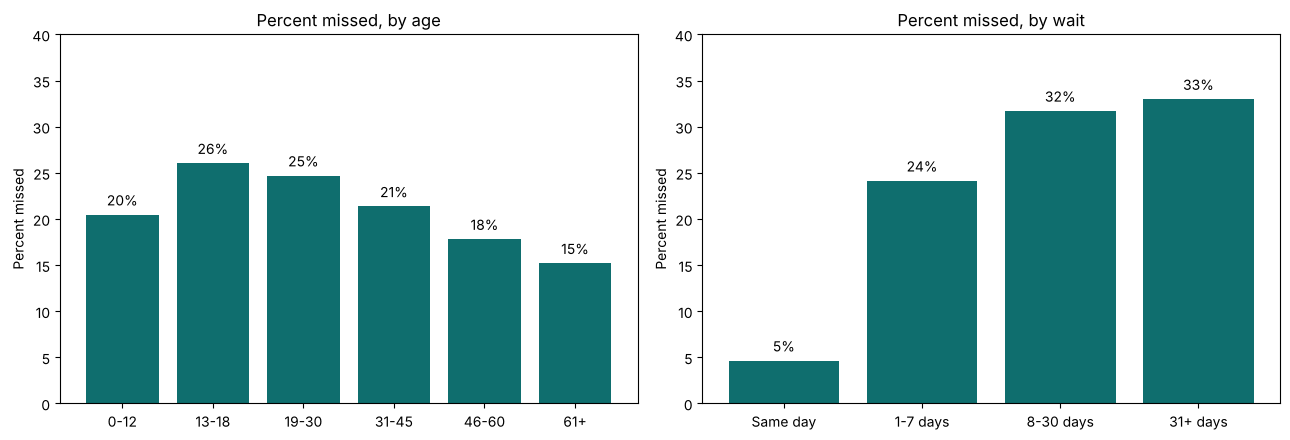

In [16]:
age_group = pd.cut(clean["Age"], [-1, 12, 18, 30, 45, 60, 120],
                   labels=["0-12", "13-18", "19-30", "31-45", "46-60", "61+"])
wait_group = pd.cut(clean["wait_days"], [-1, 0, 7, 30, 200],
                    labels=["Same day", "1-7 days", "8-30 days", "31+ days"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, groups, title in [(axes[0], age_group, "Percent missed, by age"),
                          (axes[1], wait_group, "Percent missed, by wait")]:
    rate = clean.groupby(groups, observed=True)["missed"].mean() * 100
    ax.bar(rate.index.astype(str), rate.values, color="#0f6e6e")
    ax.set_title(title)
    ax.set_ylabel("Percent missed")
    ax.set_ylim(0, 40)
    for i, v in enumerate(rate.values):
        ax.text(i, v + 1, f"{v:.0f}%", ha="center")
plt.tight_layout()
plt.show()

**What to notice.**
- **Age:** teenagers (13 to 18) miss most often, about 26 percent. Patients over 60 miss least, about 15 percent.
- **Wait:** same-day appointments are missed about **5 percent** of the time. Waits over a week are missed about **a third** of the time. This is the strongest pattern in the dataset.

`wait_days` was not in the original data. We built it in Step 6 from two date columns. Creating a useful new column like this is **feature engineering**, and here it beats every column the clinic recorded.

In [17]:
for column in ["Gender", "Scholarship", "Hypertension", "Diabetes"]:
    print(f"Percent missed, by {column}:")
    print((clean.groupby(column)["missed"].mean() * 100).round(1))
    print()

print("Percent missed, by day of the week:")
print((clean.groupby(clean["AppointmentDay"].dt.day_name())["missed"].mean() * 100).round(1))

Percent missed, by Gender:
Gender
F    20.3
M    20.0
Name: missed, dtype: float64

Percent missed, by Scholarship:
Scholarship
0    19.8
1    23.7
Name: missed, dtype: float64

Percent missed, by Hypertension:
Hypertension
0    20.9
1    17.3
Name: missed, dtype: float64

Percent missed, by Diabetes:
Diabetes
0    20.4
1    18.0
Name: missed, dtype: float64

Percent missed, by day of the week:
AppointmentDay
Friday       21.2
Monday       20.6
Saturday     23.1
Thursday     19.3
Tuesday      20.1
Wednesday    19.7
Name: missed, dtype: float64


**What to notice.**
- **Gender and day of the week barely matter.** Women and men miss at the same rate. Every weekday falls between 19 and 21 percent. (Saturday shows 23 percent, but from only 39 appointments, too few to trust.) Finding that a column does **not** matter is a real result. It tells you what a model can ignore.
- **Patients with hypertension or diabetes miss less often.** Patients managing a chronic condition may keep appointments more carefully.
- **Scholarship patients miss more often:** 23.7 percent versus 19.8 percent. Scholarship marks a low-income family. A model that uses it may be using income as a reason to give someone a worse slot. That is **proxy bias**, from Section 3 of the lecture. Ask whether the column should be used at all.

## Step 14. A pattern that fools you
**What this does.** We compare the miss rate for patients who did and did not get an SMS (Short Message Service, meaning a text message) reminder.

In [18]:
print("Percent missed, by text reminder (0 = no text, 1 = got a text):")
print((clean.groupby("SMS_received")["missed"].mean() * 100).round(1))

Percent missed, by text reminder (0 = no text, 1 = got a text):
SMS_received
0    16.7
1    27.6
Name: missed, dtype: float64


**What to notice.** Patients who got a text missed **more** often: 27.6 percent versus 16.7 percent. Do reminders make people skip appointments?

Before you believe it, check **who** got a text.

In [19]:
print("Share who got a text, by wait:")
print(clean.groupby(pd.cut(clean["wait_days"], [-1, 2, 7, 30, 200],
                           labels=["0-2 days", "3-7 days", "8-30 days", "31+ days"]),
                    observed=True)["SMS_received"].mean().round(2))
print()
long_wait = clean[clean["wait_days"] >= 3]
print("Percent missed, by text reminder, ONLY for waits of 3 days or more:")
print((long_wait.groupby("SMS_received")["missed"].mean() * 100).round(1))

Share who got a text, by wait:
wait_days
0-2 days     0.00
3-7 days     0.57
8-30 days    0.60
31+ days     0.62
Name: SMS_received, dtype: float64

Percent missed, by text reminder, ONLY for waits of 3 days or more:
SMS_received
0    32.7
1    27.6
Name: missed, dtype: float64


**What to notice.**
- **Nobody with a wait under 3 days got a text.** The clinics texted only patients booked further ahead.
- Same-day patients almost always show up, and none of them got a text. That alone made texts look bad.
- Compare like with like, waits of 3 days or more: patients **with** a text missed **27.6 percent**, and patients **without** one missed **32.7 percent**. Reminders help.

**Lesson:** the data recorded a clinic **policy** (text only long-wait patients), not the effect of a text. A model trained on this would learn "a text reminder means the patient will likely miss." That is a **measurement** problem, and only someone who knows how the data was collected can catch it.

## Step 15. The same patients appear again and again
**What this does.** We count appointments per patient. This decides how the data must be split before training.

In [20]:
per_patient = clean["PatientId"].value_counts()
print("Appointments:      ", f"{len(clean):,}")
print("Different patients:", f"{per_patient.size:,}")
print("Most appointments for one patient:", per_patient.max())
share = (clean["PatientId"].map(per_patient) > 1).mean()
print(f"Share of appointments from patients who appear more than once: {share:.0%}")

Appointments:       110,521
Different patients: 62,298
Most appointments for one patient: 88
Share of appointments from patients who appear more than once: 66%


**What to notice.** 110,521 appointments come from 62,298 patients. One patient has **88** appointments in 27 days. Two thirds of all rows belong to patients who appear more than once.

**Why it matters.** Split this data randomly into training and test sets, and the same patient lands in both. The model can learn to recognize **patients** instead of what predicts a missed appointment, and the test score can look better than it should. This is the leak from Section 5 of the lecture. **Split by patient.** Part 3 does exactly that.

---
# Part 3: Split, train, and test
Everything so far happened **before** training. Now we train a simple model and test it on appointments it has never seen.

**The model** is a **decision tree**: a short series of yes/no questions the computer learns from the training data, such as "Is the wait more than 3 days?" and then "Is the patient under 30?" Each path through the questions ends in a prediction: shows up or misses.

**scikit-learn** is the standard Python tool for training models like this one.

## Step 16. Choose the columns the model may use
**What this does.** A model may only use information that exists **when the appointment is booked**. That is when the clinic would use a prediction, for example to send a reminder.

We leave out the patient and appointment ID numbers (they are labels, not information), our review flags, and the answer itself, `missed`.

In [21]:
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.tree import DecisionTreeClassifier

clean["male"] = (clean["Gender"] == "M").astype(int)   # turn Gender into a 0/1 number

FEATURES = ["Age", "male", "wait_days", "SMS_received", "Scholarship",
            "Hypertension", "Diabetes", "Alcoholism", "Disability_count"]
X = clean[FEATURES]      # what the model sees
y = clean["missed"]      # the answer it must learn to predict
print("Columns the model may use:", FEATURES)

Columns the model may use: ['Age', 'male', 'wait_days', 'SMS_received', 'Scholarship', 'Hypertension', 'Diabetes', 'Alcoholism', 'Disability_count']


## Step 17. Split the data by patient
**What this does.** We hold back 20 percent of the data as the **test set**, appointments the model never sees during training. We split **by patient**, so every appointment for a given patient lands on the same side.

Then, for comparison, we count what a plain random split would have done.

In [22]:
# Split by patient: each patient goes entirely to training or entirely to test
splitter = GroupShuffleSplit(test_size=0.2, random_state=1)
train_idx, test_idx = next(splitter.split(X, y, groups=clean["PatientId"]))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

shared = set(clean["PatientId"].iloc[train_idx]) & set(clean["PatientId"].iloc[test_idx])
print(f"Training appointments: {len(X_train):,}")
print(f"Test appointments:     {len(X_test):,}")
print("Patients in BOTH sets, split by patient:", len(shared))

# For comparison: a plain random split
rand_train, rand_test = train_test_split(clean, test_size=0.2, random_state=1)
shared_random = set(rand_train["PatientId"]) & set(rand_test["PatientId"])
share_rows = rand_test["PatientId"].isin(shared_random).mean()
print(f"Patients in BOTH sets, random split: {len(shared_random):,}")
print(f"Share of random test appointments whose patient is also in training: {share_rows:.0%}")

Training appointments: 88,434
Test appointments:     22,087
Patients in BOTH sets, split by patient: 0


Patients in BOTH sets, random split: 10,437
Share of random test appointments whose patient is also in training: 60%


**What to notice.** Split by patient, **zero** patients appear in both sets. A random split would have put more than 10,000 patients in both, so most test appointments would belong to patients the model had already studied. That is the leak from Section 5. From here on we use the split by patient.

## Step 18. Set the bar: a model that always guesses "shows up"
**What this does.** Before training anything, find the score of the laziest possible guess. Any real model has to beat it.

In [23]:
baseline = (y_test == 0).mean()
print(f"Always guess 'shows up': accuracy {baseline:.1%}, missed appointments caught: 0%")

Always guess 'shows up': accuracy 79.8%, missed appointments caught: 0%


**What to notice.** About **80 percent** accuracy with no model at all, because about 80 percent of patients show up. Remember the fraud model from the opening problem. A high accuracy number can mean nothing.

## Step 19. Train a small decision tree
**What this does.** We train a tree with 3 levels of yes/no questions on the training set. Then we test it on the test set and report two numbers:
- **Accuracy:** the share of all test appointments it predicted correctly.
- **Missed appointments caught:** of the patients who really missed, the share the model flagged. This is the number the clinic cares about.

In [24]:
def report(name, model):
    pred = model.predict(X_test)
    accuracy = (pred == y_test).mean()
    caught = pred[y_test.values == 1].mean()
    flagged = pred.mean()
    print(f"{name}: accuracy {accuracy:.1%} | missed appointments caught {caught:.0%} | appointments flagged {flagged:.0%}")

small_tree = DecisionTreeClassifier(max_depth=3, random_state=0)
small_tree.fit(X_train, y_train)          # learn from the training set only
report("Small tree", small_tree)          # test on appointments it has never seen

Small tree: accuracy 79.8% | missed appointments caught 0% | appointments flagged 0%


**What to notice.** About **80 percent** accuracy, the same as guessing "shows up" for everyone. And it caught **0 percent** of missed appointments. The model learned that the safest way to be right is to never predict a miss. Accuracy alone would have fooled us.

## Step 20. Tell the model that missed appointments matter
**What this does.** `class_weight="balanced"` tells the model to count a mistake on a missed appointment as seriously as a mistake on a kept one, even though misses are rare.

In [25]:
balanced_tree = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=0)
balanced_tree.fit(X_train, y_train)
report("Balanced tree", balanced_tree)

Balanced tree: accuracy 60.1% | missed appointments caught 79% | appointments flagged 52%


**What to notice.** Now it catches about **79 percent** of missed appointments. But accuracy fell to about **60 percent**, and it flags about **half** of all appointments. That is the sepsis alert's problem from the lecture: catch more real cases, and you also raise more false alarms.

Which is better depends on what the clinic does with a flag. A reminder text costs almost nothing, so flagging half the patients is fine. Double-booking half the schedule is not. That is a decision for people who know the clinic, not for the math.

## Step 21. Why we test on data the model has never seen
**What this does.** We let a tree grow with no limit on its questions. Then we score it twice: on the training set it learned from, and on the test set.

In [26]:
big_tree = DecisionTreeClassifier(random_state=0)   # no limit on the number of questions
big_tree.fit(X_train, y_train)
train_acc = (big_tree.predict(X_train) == y_train).mean()
test_acc = (big_tree.predict(X_test) == y_test).mean()
print(f"Accuracy on the training set: {train_acc:.1%}")
print(f"Accuracy on the test set:     {test_acc:.1%}")

Accuracy on the training set: 86.9%
Accuracy on the test set:     76.1%


**What to notice.** The big tree scores much higher on the data it trained on than on new data. It memorized details of the training appointments that do not carry over to new patients. If we had tested it on its own training data, we would have believed a score it cannot deliver. That is why the test set exists.

## Step 22. A leak: a column that already knows the answer
**What this does.** Suppose someone adds a helpful-looking column: each patient's miss rate, computed from **all** of their appointments. That calculation includes the appointment we are trying to predict, so the column contains part of the answer.

In [27]:
clean["patient_miss_rate"] = clean.groupby("PatientId")["missed"].transform("mean")   # uses the answer!
X_leak = clean[FEATURES + ["patient_miss_rate"]]
leaky_tree = DecisionTreeClassifier(max_depth=3, random_state=0)
leaky_tree.fit(X_leak.iloc[train_idx], y_train)
pred = leaky_tree.predict(X_leak.iloc[test_idx])
print(f"Leaky tree: accuracy {(pred == y_test).mean():.1%} | missed appointments caught {pred[y_test.values == 1].mean():.0%}")

Leaky tree: accuracy 91.8% | missed appointments caught 79%


**What to notice.** Accuracy jumps to about **92 percent**, and the model catches about four out of five missed appointments. It looks like a breakthrough. It is a leak. When a real patient books a new appointment, nobody knows yet whether they will miss it, so this column cannot exist at prediction time. The score is fake.

**Rule from the lecture:** if a column would not exist at the moment of prediction, it does not belong in training. A score that looks too good is a reason to check, not to celebrate.

## What we learned
| Part | Finding |
|---|---|
| Check | No blank cells, but disguised gaps: no appointment times, age 0, an undocumented disability code |
| Check | Impossible values: age -1, appointments before booking, decimal patient IDs |
| Check | 1,334 repeat bookings, 29 with conflicting labels |
| Clean | 6 rows removed, the rest flagged and documented |
| Explore | Wait time is the best clue to a missed appointment, and we had to build it ourselves |
| Explore | Text reminders look harmful until you compare like with like |
| Explore | Scholarship may act as a proxy for income |
| Explore | Patients repeat, so the data must be split by patient |
| Test | Split by patient: zero patients in both sets |
| Test | A small model matched the lazy guess, about 80 percent, and caught no missed appointments |
| Test | Catching more misses meant more false alarms |
| Test | A model scores higher on its own training data than on new data |
| Test | A column built from the answer produced a fake 92 percent |

## Discussion questions
1. The NaN check found zero missing values. Name three kinds of missing information this dataset still has.
2. Why does Part 1 find every problem before changing anything? What could go wrong if you cleaned as you went?
3. Explain to someone who has not seen this notebook why text reminders do not cause missed appointments, even though patients who got texts missed more often.
4. Should a clinic's model use the Scholarship column? Argue one side.
5. A clinic on your base wants to use a model trained on this data. Name two reasons it might not work there. Use the quality dimensions.
6. The small tree in Step 19 scored about 80 percent. Explain to a clinic manager why that score is not good news.
7. In Step 20, would you rather flag half the patients or catch fewer missed appointments? Your answer should depend on what the clinic does with a flag. Explain.